# CALCE CX2 — Final Transformer–PINN–GWO Optimization Study

**Complete, self-contained Jupyter notebook** for 1-, 3-, and 5-cycle-ahead SOH forecasting from five charge-derived features.

### Experiments
- Matched **Transformer + MSE** and **Transformer–PINN + MSE** reference models.
- **Huber** versus MSE; monotonicity-only, smoothness-only, and combined-loss ablations.
- **GWO** versus **budget-matched random search**, including shared versus horizon-specific physics weights.
- Optional **gradient-norm-aware dynamic physics scaling**, with gradient cosine diagnostics.
- Optional **monotonic latent trend + unconstrained residual** prediction head.
- **Fixed** battery-disjoint train/validation/test split, or **7-fold leave-one-battery-out (LOBO)** using an internal held-out validation cell.
- Save the best checkpoints, fold-local scaling, GWO trajectories, per-horizon predictions, metrics, and research plots.

**Scientific constraints:** These are *soft degradation-inspired penalties*, not electrochemical governing PDEs. An increase in measured accessible capacity is not automatically an error. Search/early stopping use **only validation cells**; outer test cells are *reporting only*. Missing or long timestamp gaps are never treated as verified rest.

**Execution:** `RUN_MODE='smoke'` checks wiring; change to `'full'` for real training. Begin with `EVAL_PROTOCOL='fixed'` and then `'lobo'`. The full GWO + random-search comparison across 7 cells is computationally substantial; you can disable optional ablations to reduce cost.

## 1 · Dependencies and configurable experiment settings

In [1]:
# Uncomment once per environment if dependencies are missing:
# %pip install numpy pandas matplotlib scikit-learn torch joblib

In [2]:
from pathlib import Path

DATA_DIR = Path(r"C:\Projects\Battery_Soh\pre processed ready to use data")
if not DATA_DIR.is_dir():
    for candidate in (Path.cwd()/"pre processed ready to use data", Path('/mnt/data/pre processed ready to use data'),Path.cwd()):
        if (candidate/'train.csv').exists() and (candidate/'validation.csv').exists():
            DATA_DIR = candidate
            break

RUN_MODE = 'full'       # 'smoke' or 'full'
EVAL_PROTOCOL = 'fixed' # 'fixed' or 'lobo'

FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
HORIZONS = (1,3,5)
LOOKBACK = 12
USE_TIME = True
BREAK_ON_SOURCE_CHANGE = False
MAX_GAP_HOURS = 24.0
FILTER_TRAIN_JUMPS = True
SOH_JUMP_THRESHOLD = 0.03

SEEDS = (42,123,2026)
MODEL_HIDDEN = 48
MODEL_HEADS = 4
MODEL_LAYERS = 2
MODEL_DROPOUT = 0.10
LR = 1e-3
BATCH_SIZE = 128
EPOCHS = 75
PATIENCE = 12
HUBER_DELTA = 0.02
WEIGHT_DECAY = 1e-4

# Fixed baseline: two horizon-specific monotonic terms and a smoothness term.
FIXED_WEIGHTS = (0.20,0.20,0.05)
# GWO searches 3 independent coefficients; the shared-weight ablation ties the first two.
GWO_WOLVES = 6
GWO_ITERS = 5
PROXY_EPOCHS = 7
REFINE_TOP_K = 2
REFINE_EPOCHS = 15
SEARCH_SEED = 117
SEARCH_REPEATS = (117,)  # increase to (117, 211) for less noisy tuning
# All search methods use the same train/validation folds and equivalent evaluation budgets.
SEARCH_BACKENDS = ('gwo','random')

RUN_EXTENDED_ABLATIONS = True
RUN_GRAD_BALANCE = True
RUN_TREND_RESIDUAL = True
RUN_OLS_CONTROL = True

if RUN_MODE == 'smoke':
    SEEDS=(42,)
    EPOCHS,PATIENCE=1,1
    GWO_WOLVES,GWO_ITERS=3,1
    PROXY_EPOCHS=1
    REFINE_TOP_K,REFINE_EPOCHS=1,1
    SEARCH_REPEATS=(117,)
    MAX_TRAIN_BATCHES=2
    MAX_EVAL_BATCHES=2
else:
    MAX_TRAIN_BATCHES=None
    MAX_EVAL_BATCHES=None

RESULTS_DIR = DATA_DIR/'transformer_pinn_gwo_final_optimization'/f'{EVAL_PROTOCOL}_{RUN_MODE}'
RESULTS_DIR.mkdir(parents=True,exist_ok=True)
(RESULTS_DIR/'checkpoints').mkdir(exist_ok=True)
(RESULTS_DIR/'predictions').mkdir(exist_ok=True)
print('Input:',DATA_DIR,'\nOutput:',RESULTS_DIR,'\nMode:',RUN_MODE,'\nProtocol:',EVAL_PROTOCOL)

Input: C:\Projects\Battery_Soh\pre processed ready to use data 
Output: C:\Projects\Battery_Soh\pre processed ready to use data\transformer_pinn_gwo_final_optimization\fixed_full 
Mode: full 
Protocol: fixed


## 2 · Imports and deterministic execution

In [3]:
import json, time, random, warnings, math
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Torch',torch.__version__,'device',DEVICE)
if DEVICE.type=='cuda': print('GPU:',torch.cuda.get_device_name(0))

def set_seed(seed):
    random.seed(int(seed)); np.random.seed(int(seed)); torch.manual_seed(int(seed))
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(int(seed))

def json_dump(path,record):
    def serialize(o):
        if isinstance(o,np.generic):return o.item()
        if isinstance(o,np.ndarray):return o.tolist()
        if isinstance(o,Path):return str(o)
        raise TypeError(str(type(o)))
    Path(path).write_text(json.dumps(record,indent=2,default=serialize),encoding='utf-8')

set_seed(42)

Torch 2.11.0+cu128 device cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 3 · Data integrity, training-only filtering and folds

In [4]:
NEEDED=['battery','cycle_ordinal','cycle_start','soh']+FEATURES

def read_data(file):
    d=pd.read_csv(DATA_DIR/file)
    missing=set(NEEDED)-set(d.columns)
    if missing:raise ValueError(f'{file}: missing columns {sorted(missing)}')
    d['cycle_start']=pd.to_datetime(d['cycle_start'],errors='raise')
    for c in FEATURES+['cycle_ordinal','soh']: d[c]=pd.to_numeric(d[c],errors='raise')
    if not np.isfinite(d[FEATURES+['cycle_ordinal','soh']].to_numpy(dtype='float64')).all():
        raise ValueError(f'{file}: NaN/infinite data')
    if d.duplicated(['battery','cycle_ordinal']).any():
        raise ValueError(f'{file}: duplicated battery/cycle_ordinal keys; audit raw data before proceeding')
    return d.sort_values(['battery','cycle_ordinal']).reset_index(drop=True)

def training_only_filter(d):
    d=d.sort_values(['battery','cycle_ordinal']).reset_index(drop=True).copy()
    g=d.groupby('battery',sort=False)
    jump=g.cycle_ordinal.diff().eq(1)&g.soh.diff().abs().gt(SOH_JUMP_THRESHOLD)
    pre=jump.groupby(d.battery).shift(-1,fill_value=False)
    removed=jump|pre
    return d.loc[~removed].copy(),d.loc[removed].copy()

raw_train=read_data('train.csv')
raw_val=read_data('validation.csv')
raw_test=read_data('test.csv')
all_raw=pd.concat([raw_train,raw_val,raw_test],ignore_index=True)
if all_raw.duplicated(['battery','cycle_ordinal']).any():raise ValueError('Cycle duplicated across splits')
assert set(raw_train.battery).isdisjoint(raw_val.battery)
assert set(raw_train.battery).isdisjoint(raw_test.battery)
assert set(raw_val.battery).isdisjoint(raw_test.battery)

if FILTER_TRAIN_JUMPS and (DATA_DIR/'train_final_filtered.csv').exists():
    fixed_train=read_data('train_final_filtered.csv')
    assert set(fixed_train.battery).issubset(set(raw_train.battery))
    filter_source='user-provided train_final_filtered.csv'
elif FILTER_TRAIN_JUMPS:
    fixed_train,_=training_only_filter(raw_train)
    filter_source='reconstructed training-only 3pp threshold (original CSV untouched)'
else:
    fixed_train=raw_train.copy();filter_source='unfiltered training'

print('Rows:',{'raw_train':len(raw_train),'fixed_train':len(fixed_train),'validation':len(raw_val),'test':len(raw_test)})
print('Filter:',filter_source)
print('Cells:',sorted(all_raw.battery.unique()))
print('Training-only Pearson correlations:')
display(fixed_train[FEATURES+['soh']].corr().loc[FEATURES,['soh']])

def build_folds():
    if EVAL_PROTOCOL=='fixed':
        return [('CX2_38_fixed',fixed_train,raw_val,raw_test)]
    if EVAL_PROTOCOL!='lobo':raise ValueError('EVAL_PROTOCOL must be fixed or lobo')
    batteries=sorted(all_raw.battery.unique()); folds=[]
    for i,outer_cell in enumerate(batteries):
        valid_cell=batteries[(i+1)%len(batteries)]
        tr=all_raw.loc[~all_raw.battery.isin([outer_cell,valid_cell])].copy()
        if FILTER_TRAIN_JUMPS:tr,_=training_only_filter(tr)
        va=all_raw.loc[all_raw.battery==valid_cell].copy()
        te=all_raw.loc[all_raw.battery==outer_cell].copy()
        folds.append((f'test_{outer_cell}_val_{valid_cell}',tr,va,te))
    return folds
folds=build_folds()
print('Folds:',[f[0] for f in folds])

Rows: {'raw_train': 7790, 'fixed_train': 7690, 'validation': 1743, 'test': 1477}
Filter: user-provided train_final_filtered.csv
Cells: ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_36', 'CX2_37', 'CX2_38']
Training-only Pearson correlations:


,soh
cc_duration_s,0.995874
cv_duration_s,-0.783578
dva_peak,-0.801793
ic_peak_voltage,-0.818887
ic_peak_width,-0.720481


Folds: ['CX2_38_fixed']


## 4 · Strictly contiguous time-series windows

All models receive *identical* 12-cycle historical windows. A window never crosses battery boundaries, skipped ordinals, invalid times, or gaps over `MAX_GAP_HOURS`. Features and elapsed-time scaling are fit only on training cells. Targets are future measured SOH for the next 1, 3, and 5 physical cycles. We **do not** give the model future charging features or past SOH labels as inputs.

In [5]:
def iter_segments(frame):
    for battery,g in frame.groupby('battery',sort=True):
        g=g.sort_values('cycle_ordinal').reset_index(drop=True)
        cycle_diff=g.cycle_ordinal.diff()
        hour_diff=g.cycle_start.diff().dt.total_seconds()/3600
        splits=cycle_diff.ne(1)|hour_diff.le(0)|hour_diff.gt(MAX_GAP_HOURS)
        if BREAK_ON_SOURCE_CHANGE and 'source_identifiers' in g:
            src=g.source_identifiers.astype(str)
            splits=splits|src.ne(src.shift(1))
        for _,part in g.groupby(splits.cumsum()):
            if len(part)>=LOOKBACK+max(HORIZONS):
                yield str(battery),part.reset_index(drop=True)

class SOHWindows(Dataset):
    def __init__(self,frame,scaler,dt_scale):
        xs,dts,ys,metadata=[],[],[],[]
        for battery,p in iter_segments(frame):
            x=scaler.transform(p[FEATURES]).astype('float32')
            target=p.soh.to_numpy(dtype='float32')
            cycles=p.cycle_ordinal.to_numpy(dtype='int64')
            hours=p.cycle_start.diff().dt.total_seconds().div(3600).to_numpy(dtype='float64')
            dt=np.ones(len(p),dtype='float32')
            dt[1:]=np.clip(hours[1:]/dt_scale,0,100).astype('float32')
            # Each sample origin ends at `end`, targets are at `end+h`, with no future-input exposure.
            for end in range(LOOKBACK-1,len(p)-max(HORIZONS)):
                start=end-LOOKBACK+1
                a=dt[start:end+1].copy();a[0]=1.0
                xs.append(x[start:end+1].copy());dts.append(a)
                ys.append([target[end+h] for h in HORIZONS])
                metadata.append({'battery':battery,'origin_cycle':int(cycles[end]),
                                 **{f'target_h{h}':int(cycles[end+h]) for h in HORIZONS}})
        if not xs:raise ValueError('No valid forecast windows: check splits/LOOKBACK/gap constraints')
        self.x=torch.from_numpy(np.stack(xs));self.dt=torch.from_numpy(np.stack(dts))
        self.y=torch.tensor(ys,dtype=torch.float32)
        self.meta=pd.DataFrame(metadata)
    def __len__(self):return len(self.y)
    def __getitem__(self,i):return self.x[i],self.dt[i],self.y[i]

def prepare_fold(tr,va,te):
    scaler=StandardScaler().fit(tr[FEATURES])
    training_deltas=[]
    for _,part in iter_segments(tr):
        training_deltas.extend(part.cycle_start.diff().dt.total_seconds().div(3600).dropna().tolist())
    if not training_deltas:raise ValueError('No training segments for time scale')
    dt_scale=float(np.median(training_deltas))
    packs={k:SOHWindows(d,scaler,dt_scale) for k,d in [('train',tr),('validation',va),('test',te)]}
    return packs,scaler,dt_scale

packs_demo,scaler_demo,dt_demo=prepare_fold(*folds[0][1:])
print('Forecast samples:',{k:len(v) for k,v in packs_demo.items()},'time scale (h):',round(dt_demo,3))
print('Example shape:',tuple(packs_demo['train'].x.shape))

Forecast samples: {'train': 2689, 'validation': 643, 'test': 497} time scale (h): 3.876
Example shape: (2689, 12, 5)


## 5 · Matched Transformer and trend–residual Transformer

In [6]:
MODEL_CFG={'lookback':LOOKBACK,'n_features':len(FEATURES),'use_time':USE_TIME,
           'hidden':MODEL_HIDDEN,'heads':MODEL_HEADS,'layers':MODEL_LAYERS,'dropout':MODEL_DROPOUT}

class ForecastTransformer(nn.Module):
    def __init__(self,lookback,n_features,use_time,hidden,heads,layers,dropout,trend_residual=False):
        super().__init__()
        self.use_time=use_time;self.trend_residual=trend_residual
        self.in_proj=nn.Linear(n_features+int(use_time),hidden)
        self.pos=nn.Parameter(torch.zeros(1,lookback,hidden))
        layer=nn.TransformerEncoderLayer(d_model=hidden,nhead=heads,dim_feedforward=2*hidden,
              dropout=dropout,batch_first=True,norm_first=True,activation='gelu')
        self.encoder=nn.TransformerEncoder(layer,num_layers=layers,enable_nested_tensor=False)
        if trend_residual:
            self.base=nn.Linear(hidden,1)
            self.rates=nn.Sequential(nn.Linear(hidden,hidden),nn.GELU(),nn.Linear(hidden,len(HORIZONS)))
            self.residual=nn.Sequential(nn.Linear(hidden+1,hidden),nn.GELU(),nn.Linear(hidden,1))
            # Initialize slow degradation increments close to zero, not ~0.69 SOH per step.
            nn.init.constant_(self.rates[-1].bias,-6.0)
            nn.init.constant_(self.base.bias,0.9)
        else:
            self.head=nn.Sequential(nn.Linear(hidden+1,hidden),nn.GELU(),nn.Linear(hidden,1))
        self.register_buffer('h_norm',torch.tensor(HORIZONS,dtype=torch.float32)/max(HORIZONS))
        self.register_buffer('h_intervals',torch.tensor([HORIZONS[0]]+[
            HORIZONS[j]-HORIZONS[j-1] for j in range(1,len(HORIZONS))],dtype=torch.float32))
    def forward(self,x,dt,return_parts=False):
        if self.use_time:
            x=torch.cat([x,torch.log1p(dt).unsqueeze(-1)],dim=-1)
        z=self.encoder(self.in_proj(x)+self.pos)[:,-1,:]
        b=z.shape[0]
        zrep=z.unsqueeze(1).expand(b,len(HORIZONS),z.shape[-1])
        hh=self.h_norm.view(1,-1,1).expand(b,-1,1)
        t=torch.cat((zrep,hh),dim=-1)
        if self.trend_residual:
            base=self.base(z)
            rates=torch.nn.functional.softplus(self.rates(z))*self.h_intervals.view(1,-1)
            trend=base-torch.cumsum(rates,dim=1)
            residual=.1*torch.tanh(self.residual(t).squeeze(-1))
            forecast=trend+residual
            if return_parts:return forecast,{'trend':trend,'residual':residual}
            return forecast
        forecast=self.head(t).squeeze(-1)
        if return_parts:return forecast,{'trend':torch.full_like(forecast,float('nan')),
                                         'residual':torch.full_like(forecast,float('nan'))}
        return forecast

def build_model(trend_residual=False):return ForecastTransformer(**MODEL_CFG,trend_residual=trend_residual).to(DEVICE)
for flag in [False,True]:
    model=build_model(flag)
    with torch.no_grad():
        output=model(torch.zeros(2,LOOKBACK,len(FEATURES),device=DEVICE),
                     torch.ones(2,LOOKBACK,device=DEVICE))
    print('Trend residual:',flag,'parameters:',sum(p.numel() for p in model.parameters()),'output:',tuple(output.shape))

Trend residual: False parameters: 41281 output: (2, 3)
Trend residual: True parameters: 43829 output: (2, 3)


## 6 · Physics terms and robust regression objectives

Physics penalties compare forecasts for *the same origin* at horizons 1, 3 and 5. Thus they never compare samples in a shuffled minibatch. Penalized quantities:

\[
L_{m,13}=\mathbb E\operatorname{ReLU}(\hat y_{k+3}-\hat y_{k+1})^2,\qquad
L_{m,35}=\mathbb E\operatorname{ReLU}(\hat y_{k+5}-\hat y_{k+3})^2.
\]

\[
L_{smooth}=\mathbb E\big[(\hat y_{k+5}-\hat y_{k+3})/2-(\hat y_{k+3}-\hat y_{k+1})/2\big]^2.
\]

This is a **forecast-horizon prior**, not verification that *measured* SOH is monotone. Losses are mean per batch; Huber operates in fractional SOH units. GWO weights are nonnegative.

In [7]:
def physical_terms(pred):
    d13=pred[:,1]-pred[:,0]
    d35=pred[:,2]-pred[:,1]
    mono13=torch.relu(d13).square().mean()
    mono35=torch.relu(d35).square().mean()
    smooth=(d35/2-d13/2).square().mean()
    return torch.stack([mono13,mono35,smooth])

def supervised_loss(pred,target,loss_name='mse'):
    if loss_name=='mse':return torch.mean((pred-target).square())
    if loss_name=='huber':return nn.functional.huber_loss(pred,target,delta=HUBER_DELTA)
    raise ValueError(loss_name)

def combined_objective(pred,target,weights=(0,0,0),loss_name='mse',grad_scale=1.):
    data=supervised_loss(pred,target,loss_name)
    phys=physical_terms(pred)
    penalty=(torch.as_tensor(weights,dtype=phys.dtype,device=phys.device)*phys).sum()
    return data+grad_scale*penalty,data,phys,penalty

def physical_diagnostics(pred):
    a=np.asarray(pred)
    inc13=a[:,1]-a[:,0];inc35=a[:,2]-a[:,1]
    violations=np.concatenate([inc13>0,inc35>0]);mags=np.concatenate([np.maximum(inc13,0),np.maximum(inc35,0)])
    return {'monotonic_violation_fraction':float(violations.mean()),
            'monotonic_violation_mean_magnitude':float(mags.mean()),
            'out_of_bounds_fraction':float(((a<0)|(a>1.1)).mean())}

def metric_calc(actual,pred):
    y=np.asarray(actual).ravel(); p=np.asarray(pred).ravel()
    return {'RMSE':float(np.sqrt(np.mean((y-p)**2))),
            'MAE':float(np.mean(np.abs(y-p))),
            'MAPE':float(100*np.mean(np.abs(y-p)/np.maximum(np.abs(y),1e-6))),
            'R2':float(r2_score(y,p))}

# Test that monotonicity uses within-example horizon comparisons, not batch order.
test_pred=torch.tensor([[.9,.8,.7],[.9,1.0,.95]],dtype=torch.float32)
assert physical_terms(test_pred)[0]>0
assert physical_terms(test_pred.flip(0)).allclose(physical_terms(test_pred))

## 7 · Training, early stopping, gradient diagnostics, checkpoints

In [8]:
def dataloaders(packs,seed):
    gen=torch.Generator().manual_seed(int(seed))
    return {'train':DataLoader(packs['train'],batch_size=BATCH_SIZE,shuffle=True,generator=gen,num_workers=0),
            'validation':DataLoader(packs['validation'],batch_size=512,shuffle=False,num_workers=0),
            'test':DataLoader(packs['test'],batch_size=512,shuffle=False,num_workers=0)}

@torch.no_grad()
def evaluate_model(model,loader,max_batches=None):
    model.eval();targets=[];predicts=[]
    for j,(x,dt,y) in enumerate(loader):
        if max_batches is not None and j>=max_batches:break
        predictions=model(x.to(DEVICE),dt.to(DEVICE)).cpu().numpy()
        predicts.append(predictions);targets.append(y.numpy())
    if not predicts:raise ValueError('No evaluation batches')
    return np.concatenate(targets,axis=0),np.concatenate(predicts,axis=0)

def cosine_of_gradients(model,data,physics):
    params=[p for p in model.parameters() if p.requires_grad]
    gd=torch.autograd.grad(data,params,retain_graph=True,allow_unused=True)
    gp=torch.autograd.grad(physics,params,retain_graph=True,allow_unused=True)
    a=torch.cat([g.detach().flatten() for g in gd if g is not None])
    b=torch.cat([g.detach().flatten() for g in gp if g is not None])
    norm_a=torch.linalg.vector_norm(a);norm_b=torch.linalg.vector_norm(b)
    cos=float(torch.dot(a,b)/(norm_a*norm_b+1e-12))
    ratio=float((norm_a/(norm_b+1e-12)).clamp(.1,10))
    return cos,ratio

def train_model(packs,seed,variant,weights=(0,0,0),loss_name='mse',trend_residual=False,
                grad_balance=False,epochs=None,patience=None,save_path=None,scaler=None,dt_scale=None):
    set_seed(seed)
    epochs=EPOCHS if epochs is None else int(epochs)
    patience=PATIENCE if patience is None else int(patience)
    ld=dataloaders(packs,seed)
    model=build_model(trend_residual)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    best_rmse=float('inf');best_state=None;best_epoch=0;history=[]
    scaler_ratio=1.0;conflicts=[];start=time.perf_counter();stall=0
    for epoch in range(1,epochs+1):
        model.train();accum=0.;seen=0
        for batch_idx,(x,dt,y) in enumerate(ld['train']):
            if MAX_TRAIN_BATCHES is not None and batch_idx>=MAX_TRAIN_BATCHES:break
            x,dt,y=x.to(DEVICE),dt.to(DEVICE),y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            forecast,parts=model(x,dt,return_parts=True)
            total,data,phys,penalty=combined_objective(forecast,y,weights,loss_name)
            if grad_balance and batch_idx%10==0 and float(penalty.detach())>0:
                cosine,ratio=cosine_of_gradients(model,data,penalty)
                conflicts.append(cosine)
                # Bound update scale; calculate gradients before calling backward.
                scaler_ratio=0.8*scaler_ratio+0.2*ratio
                total=data+scaler_ratio*penalty
            if trend_residual:
                # Prevent trivial high-amplitude residual from undermining the monotonic trend prior.
                total=total+0.002*parts['residual'].square().mean()
            if not bool(torch.isfinite(total)):
                raise FloatingPointError(f'Non-finite loss: {variant}, seed={seed}')
            total.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.)
            optimizer.step()
            accum+=float(total.detach())*len(y);seen+=len(y)
        yt,yp=evaluate_model(model,ld['validation'],MAX_EVAL_BATCHES)
        vrmse=metric_calc(yt,yp)['RMSE']
        history.append({'variant':variant,'seed':seed,'epoch':epoch,'train_loss':accum/max(seen,1),
                        'validation_rmse':vrmse,'gradient_scale':scaler_ratio})
        if vrmse<best_rmse-1e-9:
            best_rmse=vrmse;best_epoch=epoch;stall=0
            best_state=deepcopy({k:v.detach().cpu() for k,v in model.state_dict().items()})
        else:stall+=1
        if stall>=patience:break
    if best_state is None:raise RuntimeError('No valid checkpoint')
    model.load_state_dict(best_state)
    details={'validation_rmse':best_rmse,'best_epoch':best_epoch,
             'train_seconds':time.perf_counter()-start,'gradient_cos_mean':float(np.mean(conflicts)) if conflicts else np.nan,
             'gradient_conflict_fraction':float((np.asarray(conflicts)<0).mean()) if conflicts else np.nan}
    if save_path is not None:
        torch.save({'model_state_dict':best_state,'model_cfg':MODEL_CFG,'trend_residual':bool(trend_residual),
                    'features':FEATURES,'horizons':HORIZONS,'lookback':LOOKBACK,'weights':list(weights),
                    'loss_name':loss_name,'seed':seed,'variant':variant,'details':details,
                    'scaler_mean':None if scaler is None else scaler.mean_.tolist(),
                    'scaler_scale':None if scaler is None else scaler.scale_.tolist(),
                    'dt_scale':dt_scale},str(save_path))
    return model,pd.DataFrame(history),details

print('Ready: train_model()')

Ready: train_model()


## 8 · Better Grey Wolf Optimization versus budget-matched random search

Both optimizers minimize **inner-validation RMSE**, with identical candidate-training epochs, seed(s), zero-physics control, population size, and full-fidelity finalist budget. Candidate weights are searched in **log-like scaled coordinates** to represent low and high penalty strengths. Always use the same held-out fold and same seeds for each method. GWO is **not** used to optimize individual network parameters.

In [9]:
# Parameter 0 is an explicit no-penalty option; other weights vary roughly logarithmically.
# This map deliberately includes exact zero, which log-scale searches otherwise omit.
def scaled_to_weights(position,dimension=3):
    p=np.asarray(position,dtype='float64').reshape(-1)
    if len(p)!=dimension:raise ValueError('Invalid search dimension')
    # monotonicity weights in [0,2]; smoothness weight in [0,0.5]
    ranges=[2.,2.,0.5] if dimension==3 else [2.,0.5]
    ans=[]
    for u,upper in zip(p,ranges):
        if u<=0.015:ans.append(0.)
        else:ans.append(float(upper*(10**(3.*(u-1.)))))  # positive log-scaled [~.002,upper]
    if dimension==2:return (ans[0],ans[0],ans[1])
    return tuple(ans)

def search_weights(packs,method='gwo',dimension=3,fold='fixed'):
    if method not in ('gwo','random'):raise ValueError(method)
    rng=np.random.default_rng(SEARCH_SEED+dimension)
    # identical first two controls for both algorithms
    population=rng.random((GWO_WOLVES,dimension))
    population[0]=0.
    if GWO_WOLVES>1:population[1]=0.65
    rows=[];seen={};candidate_positions=[]
    def eval_candidate(pos,stage,iteration,wolf,epochs):
        key=(tuple(np.asarray(pos).round(6)),int(epochs))
        w=scaled_to_weights(pos,dimension)
        if key not in seen:
            scores=[]
            for search_seed in SEARCH_REPEATS:
                _,_,out=train_model(packs,search_seed,f'search_{method}',weights=w,
                                    loss_name='huber',epochs=epochs,patience=epochs)
                scores.append(out['validation_rmse'])
            seen[key]=float(np.mean(scores))
        score=seen[key]
        rows.append({'fold':fold,'method':method,'dimension':dimension,'stage':stage,
                     'iteration':iteration,'candidate':wolf,'weights':str(w),
                     'lambda_13':w[0],'lambda_35':w[1],'lambda_smooth':w[2],
                     'validation_rmse':score,'proxy_epochs':epochs})
        return score
    best_score=float('inf');best_point=None
    for iteration in range(GWO_ITERS):
        scores=np.array([eval_candidate(population[j],'proxy',iteration,j,PROXY_EPOCHS)
                         for j in range(GWO_WOLVES)])
        for j in range(GWO_WOLVES):candidate_positions.append((scores[j],population[j].copy()))
        order=np.argsort(scores)
        if scores[order[0]]<best_score:
            best_score=float(scores[order[0]]);best_point=population[order[0]].copy()
        if method=='random':
            population=rng.random((GWO_WOLVES,dimension))
            if iteration==0: population[0]=best_point.copy()
        else:
            leaders=population[order[:3]]
            a=2*(1-iteration/max(GWO_ITERS-1,1))
            successor=population.copy()
            for j in range(GWO_WOLVES):
                proposals=[]
                for leader in leaders:
                    r1=rng.random(dimension);r2=rng.random(dimension)
                    A=2*a*r1-a;C=2*r2
                    proposals.append(leader-A*np.abs(C*leader-population[j]))
                successor[j]=np.clip(np.mean(proposals,axis=0),0,1)
            successor[0]=best_point
            population=successor
    # Budget-matched refinement of top K unique proxy candidates.
    unique=[];added=set()
    for _,point in sorted(candidate_positions,key=lambda t:t[0]):
        key=tuple(point.round(6))
        if key not in added:unique.append(point);added.add(key)
        if len(unique)==REFINE_TOP_K:break
    finalists=[]
    for j,point in enumerate(unique):
        score=eval_candidate(point,'refine',GWO_ITERS,j,REFINE_EPOCHS)
        finalists.append((score,point))
    best_full_score,best_full_position=min(finalists,key=lambda t:t[0])
    best_weights=scaled_to_weights(best_full_position,dimension)
    return best_weights,pd.DataFrame(rows),{'method':method,'dimension':dimension,
        'proxy_best_rmse':best_score,'refine_best_rmse':best_full_score,
        'weights':best_weights,'candidates_evaluated':len(rows)}

for n in (2,3):
    for v in [(0,)*n,(1,)*n]:print('dimension',n,'position',v,'weights',scaled_to_weights(v,n))

dimension 2 position (0, 0) weights (0.0, 0.0, 0.0)
dimension 2 position (1, 1) weights (2.0, 2.0, 0.5)
dimension 3 position (0, 0, 0) weights (0.0, 0.0, 0.0)
dimension 3 position (1, 1, 1) weights (2.0, 2.0, 0.5)


## 9 · Experiment variants (all conditions are explicit)

The notebook runs the following on *exactly the same* eligible samples:

| Key | Data loss | Physics weights | Purpose |
|---|---|---|---|
| `transformer_mse` | MSE | None | Unconstrained reference |
| `pinn_mse_fixed` | MSE | Fixed | Existing PINN control |
| `pinn_huber_fixed` | Huber | Fixed | Isolate Huber effect |
| `pinn_huber_mono_only` | Huber | Monotonicity only | Ablation |
| `pinn_huber_smooth_only` | Huber | Smoothness only | Ablation |
| `pinn_huber_gwo_global` | Huber | GWO with shared mono weights | Test global weighting |
| `pinn_huber_gwo_horizon` | Huber | GWO with separate 1→3 / 3→5 weights | Proposed horizon-specific weighting |
| `pinn_huber_random_horizon` | Huber | Budget-matched random search | Tests optimizer choice |
| `pinn_huber_gradbalance` | Huber | Fixed + gradient-norm adjustment | Optional conflict-aware control |
| `trend_residual_huber_gwo` | Huber | GWO horizon weights | Optional structural prior |

The trend/residual head adds parameters, so any improvement requires a parameter-count caveat or a capacity-matched control. This is **not** a claim that the learned trend equals physical irreversible degradation.

In [10]:
def make_variant_configs(optimized):
    configs={
      'transformer_mse':dict(weights=(0.,0.,0.),loss_name='mse'),
      'pinn_mse_fixed':dict(weights=FIXED_WEIGHTS,loss_name='mse'),
      'pinn_huber_fixed':dict(weights=FIXED_WEIGHTS,loss_name='huber'),
      'pinn_huber_gwo_global':dict(weights=optimized['gwo_global'],loss_name='huber'),
      'pinn_huber_gwo_horizon':dict(weights=optimized['gwo_horizon'],loss_name='huber'),
      'pinn_huber_random_horizon':dict(weights=optimized['random_horizon'],loss_name='huber'),
    }
    if RUN_EXTENDED_ABLATIONS:
        configs.update({'pinn_huber_mono_only':dict(weights=(.2,.2,0.),loss_name='huber'),
                        'pinn_huber_smooth_only':dict(weights=(0.,0.,.05),loss_name='huber')})
    if RUN_GRAD_BALANCE:
        configs['pinn_huber_gradbalance']=dict(weights=FIXED_WEIGHTS,loss_name='huber',grad_balance=True)
    if RUN_TREND_RESIDUAL:
        configs['trend_residual_huber_gwo']=dict(weights=optimized['gwo_horizon'],loss_name='huber',trend_residual=True)
    return configs

print('Variants defined; actual configurations are recorded after each search.')

Variants defined; actual configurations are recorded after each search.


## 10 · Run experiments, write fold-specific results, persist models

In [11]:
search_logs=[];search_summary=[];run_metrics=[];histories=[];diag_rows=[];fold_scalers=[]

def evaluate_outputs(fold,variant,seed,model,packs):
    loads=dataloaders(packs,seed)
    for split in ('validation','test'):
        yt,yp=evaluate_model(model,loads[split],MAX_EVAL_BATCHES)
        meta=packs[split].meta.iloc[:len(yp)].copy().reset_index(drop=True)
        output=meta.copy()
        for j,h in enumerate(HORIZONS):
            output[f'soh_actual_h{h}']=yt[:,j]
            output[f'soh_prediction_h{h}']=yp[:,j]
            row={'fold':fold,'variant':variant,'seed':seed,'split':split,'horizon':h,'n_windows':len(yp)}
            row.update(metric_calc(yt[:,j],yp[:,j]))
            run_metrics.append(row)
        d=physical_diagnostics(yp)
        diag_rows.append({'fold':fold,'variant':variant,'seed':seed,'split':split,**d})
        path=RESULTS_DIR/'predictions'/f'{fold}__{variant}__seed{seed}__{split}.csv'
        output.to_csv(path,index=False)

for fold_ix,(fold_name,tr,va,te) in enumerate(folds):
    print(f'\n=== {fold_ix+1}/{len(folds)}: {fold_name} ===')
    assert set(tr.battery).isdisjoint(va.battery) and set(tr.battery).isdisjoint(te.battery)
    packs,scaler,dt_scale=prepare_fold(tr,va,te)
    fold_scalers.append({'fold':fold_name,'train_batteries':sorted(tr.battery.unique()),
                         'validation_battery':sorted(va.battery.unique()),'test_battery':sorted(te.battery.unique()),
                         'train_rows':len(tr),'train_windows':len(packs['train']),
                         'validation_windows':len(packs['validation']),'test_windows':len(packs['test']),
                         'scaler_mean':scaler.mean_.tolist(),'scaler_scale':scaler.scale_.tolist(),'time_scale_hours':dt_scale})
    opt={}
    for method,dim,alias in [('gwo',2,'gwo_global'),('gwo',3,'gwo_horizon'),('random',3,'random_horizon')]:
        w,logs,report=search_weights(packs,method=method,dimension=dim,fold=fold_name)
        opt[alias]=w
        search_logs.append(logs)
        search_summary.append({'fold':fold_name,'alias':alias,**report})
        print(alias,'selected',tuple(round(z,5) for z in w),'validation',round(report['refine_best_rmse'],6))
    variants=make_variant_configs(opt)
    for variant,config in variants.items():
        for seed in SEEDS:
            ckpt=RESULTS_DIR/'checkpoints'/f'{fold_name}__{variant}__seed{seed}.pt'
            model,history,info=train_model(packs,seed,variant,**config,save_path=ckpt,
                                            scaler=scaler,dt_scale=dt_scale)
            history.insert(0,'fold',fold_name);histories.append(history)
            print(f' {variant:29s} seed={seed} validation_RMSE={info["validation_rmse"]:.6f} epoch={info["best_epoch"]}')
            evaluate_outputs(fold_name,variant,seed,model,packs)
            for row in run_metrics[-2*len(HORIZONS):]:
                row['checkpoint']=str(ckpt)
                row.update({f'train_{k}':v for k,v in info.items()})
            del model
    print('Fold completed:',fold_name)

metrics_df=pd.DataFrame(run_metrics)
search_df=pd.concat(search_logs,ignore_index=True)
search_df.to_csv(RESULTS_DIR/'optimizer_search_history.csv',index=False)
pd.DataFrame(search_summary).to_csv(RESULTS_DIR/'optimizer_selected_weights.csv',index=False)
metrics_df.to_csv(RESULTS_DIR/'metrics_runs.csv',index=False)
pd.DataFrame(diag_rows).to_csv(RESULTS_DIR/'physics_diagnostics.csv',index=False)
pd.concat(histories,ignore_index=True).to_csv(RESULTS_DIR/'training_curves.csv',index=False)
json_dump(RESULTS_DIR/'fold_preprocessing.json',fold_scalers)
print('Saved output in',RESULTS_DIR)


=== 1/1: CX2_38_fixed ===
gwo_global selected (0.86758, 0.86758, 0.0) validation 0.018663
gwo_horizon selected (0.28102, 1.41901, 0.01451) validation 0.018666
random_horizon selected (0.86649, 0.22384, 0.05328) validation 0.01867
 transformer_mse               seed=42 validation_RMSE=0.015829 epoch=33
 transformer_mse               seed=123 validation_RMSE=0.019860 epoch=17
 transformer_mse               seed=2026 validation_RMSE=0.017190 epoch=15
 pinn_mse_fixed                seed=42 validation_RMSE=0.015851 epoch=33
 pinn_mse_fixed                seed=123 validation_RMSE=0.019909 epoch=17
 pinn_mse_fixed                seed=2026 validation_RMSE=0.016713 epoch=15
 pinn_huber_fixed              seed=42 validation_RMSE=0.015112 epoch=44
 pinn_huber_fixed              seed=123 validation_RMSE=0.011434 epoch=40
 pinn_huber_fixed              seed=2026 validation_RMSE=0.014156 epoch=15
 pinn_huber_gwo_global         seed=42 validation_RMSE=0.014942 epoch=44
 pinn_huber_gwo_global        

## 11 · Research tables, statistically paired comparisons and model selection

In [12]:
summary=(metrics_df.groupby(['split','variant','horizon'],as_index=False)
         .agg(mean_RMSE=('RMSE','mean'),std_RMSE=('RMSE','std'),
              mean_MAE=('MAE','mean'),mean_MAPE=('MAPE','mean'),mean_R2=('R2','mean'),
              n_runs=('RMSE','size')))
summary.to_csv(RESULTS_DIR/'metrics_summary.csv',index=False)
print('VALIDATION — model comparison, lower RMSE is better')
display(summary.query('split=="validation"').sort_values(['horizon','mean_RMSE']))
print('TEST — reporting only (never tune model choices here)')
display(summary.query('split=="test"').sort_values(['horizon','mean_RMSE']))

# Paired comparisons align on fold + seed + horizon; positive gain = new model improves RMSE.
base=metrics_df.query('variant=="transformer_mse"')[['fold','seed','split','horizon','RMSE']].rename(columns={'RMSE':'baseline_RMSE'})
paired=metrics_df.merge(base,on=['fold','seed','split','horizon'],how='left')
paired['gain_pct']=100*(paired.baseline_RMSE-paired.RMSE)/paired.baseline_RMSE
paired.to_csv(RESULTS_DIR/'paired_improvements.csv',index=False)

fold_macro=(metrics_df.groupby(['split','fold','variant','horizon'],as_index=False)
            .agg(fold_RMSE=('RMSE','mean'),fold_MAE=('MAE','mean')))
fold_macro.to_csv(RESULTS_DIR/'per_fold_summary.csv',index=False)
macro=(fold_macro.groupby(['split','variant','horizon'],as_index=False)
       .agg(battery_macro_RMSE=('fold_RMSE','mean'),cell_sd=('fold_RMSE','std'),
            worst_cell_RMSE=('fold_RMSE','max'),cells=('fold','nunique')))
macro.to_csv(RESULTS_DIR/'battery_macro_summary.csv',index=False)

# Select a research candidate using validation only, averaged over all forecast horizons.
selection=(metrics_df.query('split=="validation"')
           .groupby('variant',as_index=False).RMSE.mean().sort_values('RMSE'))
selection.to_csv(RESULTS_DIR/'validation_model_selection.csv',index=False)
selected_variant=str(selection.iloc[0]['variant'])
print('Validation-selected variant (across horizons):',selected_variant)
print('Physics diagnostics:')
display(pd.DataFrame(diag_rows).groupby(['split','variant'],as_index=False)[
    ['monotonic_violation_fraction','monotonic_violation_mean_magnitude','out_of_bounds_fraction']].mean())
json_dump(RESULTS_DIR/'RUN_MANIFEST.json',{
    'mode':RUN_MODE,'protocol':EVAL_PROTOCOL,'training_filter':filter_source,
    'features':FEATURES,'horizons':HORIZONS,'lookback':LOOKBACK,'time_channel':USE_TIME,
    'model_cfg':MODEL_CFG,'huber_delta':HUBER_DELTA,'seeds':SEEDS,'gwo_wolves':GWO_WOLVES,
    'gwo_iters':GWO_ITERS,'proxy_epochs':PROXY_EPOCHS,'refine_epochs':REFINE_EPOCHS,
    'search_repeats':SEARCH_REPEATS,'model_selection':selected_variant,
    'selection_rule':'mean validation RMSE over 1/3/5-cycle horizons, outer test never used'})

VALIDATION — model comparison, lower RMSE is better


,split,variant,horizon,mean_RMSE,std_RMSE,mean_MAE,mean_MAPE,mean_R2,n_runs
33,validation,pinn_huber_gradbalance,1,0.012222,0.001709,0.009153,1.301463,0.989388,3
42,validation,pinn_huber_mono_only,1,0.012231,0.001854,0.008747,1.260729,0.989347,3
30,validation,pinn_huber_fixed,1,0.012232,0.001855,0.008747,1.260766,0.989346,3
48,validation,pinn_huber_smooth_only,1,0.012295,0.001422,0.009414,1.327895,0.989303,3
45,validation,pinn_huber_random_horizon,1,0.012414,0.001975,0.008945,1.287769,0.989010,3
57,validation,trend_residual_huber_gwo,1,0.012439,0.002455,0.009513,1.337626,0.988867,3
39,validation,pinn_huber_gwo_horizon,1,0.012937,0.002082,0.009485,1.361203,0.988060,3
36,validation,pinn_huber_gwo_global,1,0.013010,0.002157,0.009537,1.369136,0.987910,3
51,validation,pinn_mse_fixed,1,0.016522,0.003378,0.012159,1.754174,0.980320,3
54,validation,transformer_mse,1,0.016575,0.003632,0.012318,1.769728,0.980116,3


TEST — reporting only (never tune model choices here)


,split,variant,horizon,mean_RMSE,std_RMSE,mean_MAE,mean_MAPE,mean_R2,n_runs
18,test,pinn_huber_smooth_only,1,0.010481,0.001376,0.008319,1.090065,0.992018,3
3,test,pinn_huber_gradbalance,1,0.011768,0.001571,0.009521,1.225532,0.989933,3
24,test,transformer_mse,1,0.012539,0.000873,0.010046,1.324268,0.988669,3
6,test,pinn_huber_gwo_global,1,0.012583,0.004246,0.010466,1.360758,0.987763,3
9,test,pinn_huber_gwo_horizon,1,0.012666,0.004211,0.010573,1.374529,0.987626,3
21,test,pinn_mse_fixed,1,0.012933,0.000191,0.010440,1.370581,0.987983,3
15,test,pinn_huber_random_horizon,1,0.013337,0.003394,0.011270,1.455900,0.986671,3
12,test,pinn_huber_mono_only,1,0.013499,0.003270,0.011428,1.475700,0.986397,3
0,test,pinn_huber_fixed,1,0.013501,0.003270,0.011429,1.475821,0.986394,3
27,test,trend_residual_huber_gwo,1,0.015105,0.004919,0.011054,1.452074,0.982451,3


Validation-selected variant (across horizons): trend_residual_huber_gwo
Physics diagnostics:


,split,variant,monotonic_violation_fraction,monotonic_violation_mean_magnitude,out_of_bounds_fraction
0,test,pinn_huber_fixed,0.223340,8.428791e-05,0.0
1,test,pinn_huber_gradbalance,0.161636,4.324963e-05,0.0
2,test,pinn_huber_gwo_global,0.084842,1.764953e-05,0.0
3,test,pinn_huber_gwo_horizon,0.060362,1.884800e-05,0.0
4,test,pinn_huber_mono_only,0.223340,8.443523e-05,0.0
5,test,pinn_huber_random_horizon,0.137827,3.293057e-05,0.0
6,test,pinn_huber_smooth_only,0.451040,2.924574e-04,0.0
7,test,pinn_mse_fixed,0.731724,9.080703e-04,0.0
8,test,transformer_mse,0.857143,1.836850e-03,0.0
9,test,trend_residual_huber_gwo,0.000000,0.000000e+00,0.0


## 12 · Visualization: per-horizon RMSE and GWO weight-search history

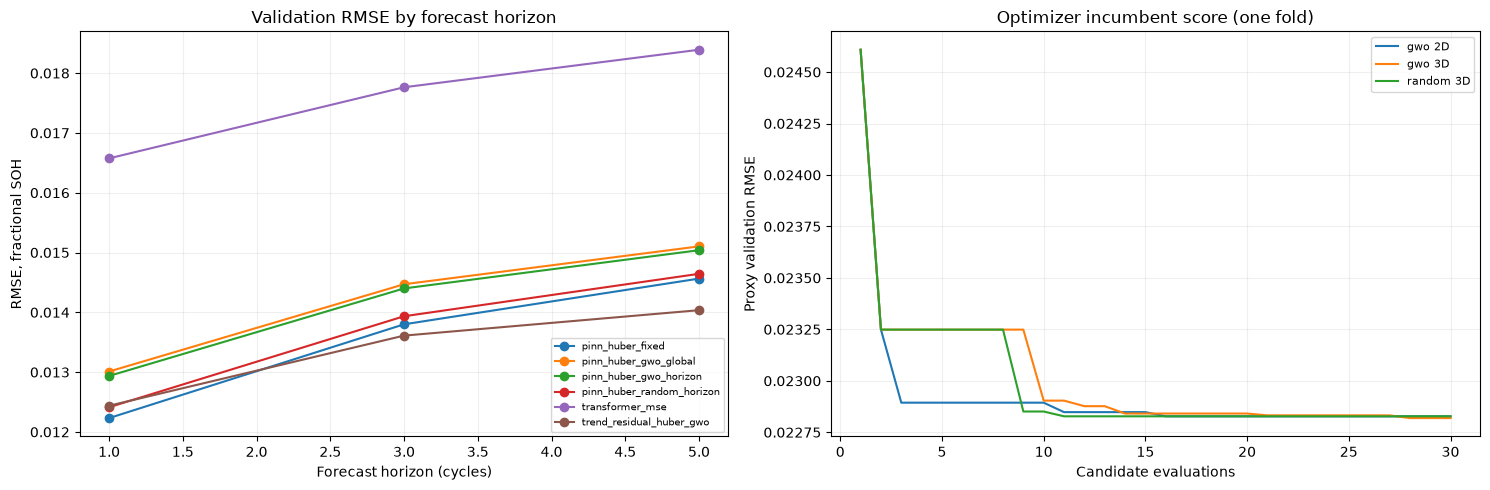

In [13]:
fig,axs=plt.subplots(1,2,figsize=(15,5))
sel=summary.query('split=="validation"')
for variant,sub in sel.groupby('variant'):
    if variant in ('transformer_mse','pinn_huber_fixed','pinn_huber_gwo_global',
                   'pinn_huber_gwo_horizon','pinn_huber_random_horizon','trend_residual_huber_gwo'):
        axs[0].plot(sub.horizon,sub.mean_RMSE,marker='o',label=variant)
axs[0].set_title('Validation RMSE by forecast horizon')
axs[0].set_xlabel('Forecast horizon (cycles)');axs[0].set_ylabel('RMSE, fractional SOH')
axs[0].legend(fontsize=7);axs[0].grid(alpha=.2)
for (method,dimension),sub in search_df.groupby(['method','dimension']):
    # Best so far from first fold; proxy only so comparison is budget aligned.
    first_fold=search_df.fold.iloc[0]
    ss=sub[(sub.fold==first_fold)&(sub.stage=='proxy')].reset_index(drop=True)
    axs[1].plot(np.arange(1,len(ss)+1),ss.validation_rmse.cummin(),label=f'{method} {dimension}D')
axs[1].set_title('Optimizer incumbent score (one fold)')
axs[1].set_xlabel('Candidate evaluations');axs[1].set_ylabel('Proxy validation RMSE')
axs[1].legend(fontsize=8);axs[1].grid(alpha=.2)
plt.tight_layout()
plt.savefig(RESULTS_DIR/'validation_and_optimizer_search.png',dpi=180)
plt.show()

if EVAL_PROTOCOL=='lobo':
    sub=fold_macro.query('split=="test" and horizon==5')
    pivot=sub.pivot(index='fold',columns='variant',values='fold_RMSE')
    cols=[x for x in ['transformer_mse','pinn_huber_gwo_horizon','pinn_huber_random_horizon'] if x in pivot]
    display(pivot[cols])

## 12B · Optional Transformer backbone sweep (validation only)

The core experiment holds the Transformer backbone matched across variants. After completing it, you can optionally compare small backbone configurations. **Do not run this sweep using test RMSE.** Select architecture parameters on the training-side validation cell(s), then rerun the full matched experiment with the chosen backbone. This optional sweep does not change `LOOKBACK` because that would change window eligibility; separately repeat the entire experiment with sequence lengths 12, 24 and 48 as a sensitivity study.

In [14]:
RUN_BACKBONE_SWEEP = False  # switch to True only when required

if RUN_BACKBONE_SWEEP:
    options = [
        {'hidden':32,'heads':4,'layers':1,'dropout':0.05,'lr':1e-3},
        {'hidden':48,'heads':4,'layers':2,'dropout':0.10,'lr':1e-3},
        {'hidden':64,'heads':4,'layers':2,'dropout':0.10,'lr':5e-4},
        {'hidden':64,'heads':4,'layers':3,'dropout':0.20,'lr':3e-4},
    ]
    old_config=MODEL_CFG.copy();old_lr=LR
    scores=[]
    try:
        # Use the first training-side validation fold, *not its outer test battery*.
        for i,opt in enumerate(options):
            MODEL_CFG.update({k:opt[k] for k in ('hidden','heads','layers','dropout')})
            LR=opt['lr']
            for seed in (42,123) if RUN_MODE=='full' else (42,):
                _,_,result=train_model(packs_demo,seed,f'backbone_option_{i}',
                                        weights=FIXED_WEIGHTS,loss_name='huber',
                                        epochs=min(EPOCHS,40),patience=min(PATIENCE,10))
                scores.append({'option':i,'seed':seed,**opt,
                               'validation_rmse':result['validation_rmse']})
    finally:
        MODEL_CFG.update(old_config);LR=old_lr
    sweep=pd.DataFrame(scores)
    sweep.to_csv(RESULTS_DIR/'optional_backbone_sweep.csv',index=False)
    display(sweep.groupby('option',as_index=False).validation_rmse.mean().sort_values('validation_rmse'))


## 12C · Actual versus predicted SOH (validation-selected model)

This diagnostic uses the *already-selected* validation winner. Plotting the held-out battery is descriptive; it is not permission to choose a different architecture based on the observed test fit.

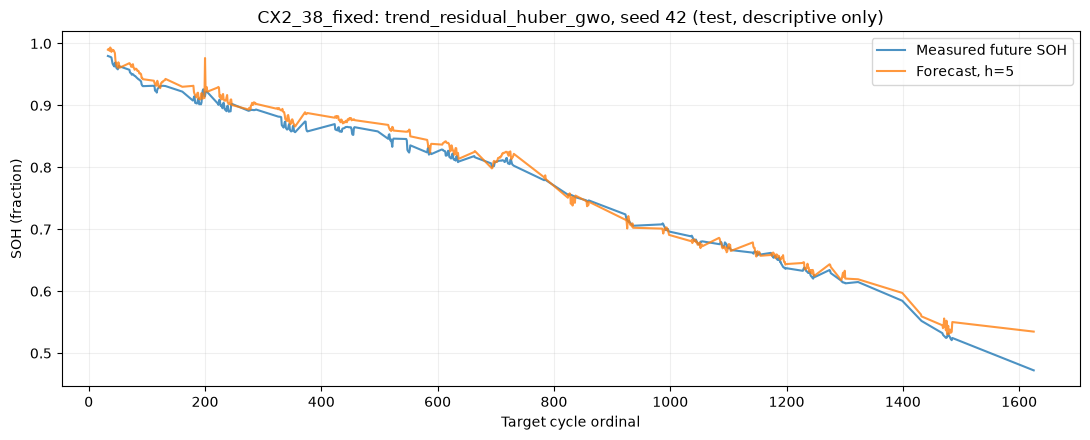

In [15]:
chosen=metrics_df.query('split=="validation" and variant==@selected_variant').sort_values('RMSE').iloc[0]
chosen_fold=chosen['fold'];chosen_seed=int(chosen['seed'])
path=RESULTS_DIR/'predictions'/f'{chosen_fold}__{selected_variant}__seed{chosen_seed}__test.csv'
plot_df=pd.read_csv(path)
fig,ax=plt.subplots(figsize=(11,4.5))
ax.plot(plot_df['target_h5'],plot_df['soh_actual_h5'],label='Measured future SOH',alpha=.8)
ax.plot(plot_df['target_h5'],plot_df['soh_prediction_h5'],label='Forecast, h=5',alpha=.8)
ax.set_title(f'{chosen_fold}: {selected_variant}, seed {chosen_seed} (test, descriptive only)')
ax.set_xlabel('Target cycle ordinal');ax.set_ylabel('SOH (fraction)');ax.grid(alpha=.2)
ax.legend();plt.tight_layout()
plt.savefig(RESULTS_DIR/'validation_selected_test_prediction_h5.png',dpi=180)
plt.show()


## 13 · Reload a checkpoint for reproducible inference

In [16]:
def load_checkpoint(path,device=DEVICE):
    # Load only locally generated/trusted checkpoints.
    saved=torch.load(path,map_location=device,weights_only=False)
    cfg=saved['model_cfg']
    model=ForecastTransformer(**cfg,trend_residual=saved['trend_residual']).to(device)
    model.load_state_dict(saved['model_state_dict']);model.eval()
    return model,saved

# Re-load the validation-selected model checkpoint as a verification example.
chosen=metrics_df.query('split=="validation" and variant==@selected_variant').sort_values('RMSE').iloc[0]
reloaded,model_info=load_checkpoint(chosen['checkpoint'])
print('Verified checkpoint:',chosen['checkpoint'])
print('Original feature order:',model_info['features'])
print('Stored scaler statistics available:',model_info['scaler_mean'] is not None)
print('Selected variant:',selected_variant)

if RUN_OLS_CONTROL:
    from sklearn.linear_model import LinearRegression
    ols_rows=[]
    for fold_name,tr,va,te in folds:
        # OLS uses last observed (pre-target) CC, CV, forecast horizon on identical windows.
        pack,scale,dt_scale=prepare_fold(tr,va,te)
        def ols_data(obj):
            latest=obj.x[:,-1,:2].numpy();hh=np.asarray(HORIZONS,dtype=float)/max(HORIZONS)
            design=np.column_stack([np.repeat(latest,len(HORIZONS),axis=0),np.tile(hh,len(latest))])
            return design,obj.y.numpy().ravel()
        Xtr,ytr=ols_data(pack['train'])
        reg=LinearRegression().fit(Xtr,ytr)
        for split in ('validation','test'):
            XX,yy=ols_data(pack[split]);pr=reg.predict(XX).reshape(-1,len(HORIZONS));actual=yy.reshape(-1,len(HORIZONS))
            for j,h in enumerate(HORIZONS):
                ols_rows.append({'fold':fold_name,'split':split,'horizon':h,**metric_calc(actual[:,j],pr[:,j])})
    ols=pd.DataFrame(ols_rows)
    ols.to_csv(RESULTS_DIR/'ols_cc_cv_control.csv',index=False)
    print('OLS (CC+CV) reference scores:')
    display(ols.groupby(['split','horizon'],as_index=False).RMSE.mean())

Verified checkpoint: C:\Projects\Battery_Soh\pre processed ready to use data\transformer_pinn_gwo_final_optimization\fixed_full\checkpoints\CX2_38_fixed__trend_residual_huber_gwo__seed42.pt
Original feature order: ['cc_duration_s', 'cv_duration_s', 'dva_peak', 'ic_peak_voltage', 'ic_peak_width']
Stored scaler statistics available: True
Selected variant: trend_residual_huber_gwo
OLS (CC+CV) reference scores:


,split,horizon,RMSE
0,test,1,0.014227
1,test,3,0.015290
2,test,5,0.015728
3,validation,1,0.008425
4,validation,3,0.010678
5,validation,5,0.011711


## 14 · Research interpretation and publication checklist

1. **Do not optimize on test results.** Select physics weights and model settings using training-side validation only. Historical CX2_38 exploration limits its status as a fully untouched external test.
2. **Search fairness:** Both GWO and random search use the same proxy candidate count and full-fidelity finalist count. Search candidates have identical seeds and train/validation windows. Report wall time as well as RMSE.
3. **GWO noise:** Proxy training on a single seed can be noisy. Increase `SEARCH_REPEATS`, but apply the same repeats to random search.
4. **Cross-horizon constraints:** Forecasts are penalized for increasing from horizon 1 to 3 or 3 to 5. This does not imply measured accessible capacity must monotonically decline.
5. **Trend+residual identifiability:** The latent trend and residual are statistical components, not independently established electrochemical states.
6. **Train-only filtering:** The 3 percentage-point rule is exploratory; only verified errors warrant permanently corrected labels. Do not smooth held-out test targets.
7. **Cross-family extension:** This notebook uses the 7 existing CX2 cells. CS2/PL/LFP/NMC work requires new protocol harmonization, equivalent feature definitions, and appropriate normalization before pooled training.
8. **Test the optimizer contribution**, not merely the effect of searching more candidate weight sets. Also keep a zero-physics control and a fixed-weight PINN.

### Recommended sequence

- Run smoke mode, confirm the output files.
- Run `full` + `fixed` as a reproducibility check.
- Run `full` + `lobo` for scientific conclusions. Check win counts, mean cell RMSE and worst-cell RMSE, not only one favorable horizon.
- Only claim a new contribution if gains survive the cross-battery experiment and literature comparison.

**Results exported:** `metrics_runs.csv`, `metrics_summary.csv`, `per_fold_summary.csv`, `battery_macro_summary.csv`, `paired_improvements.csv`, `optimizer_search_history.csv`, `optimizer_selected_weights.csv`, `physics_diagnostics.csv`, `training_curves.csv`, `validation_model_selection.csv`, `fold_preprocessing.json`, predictions, checkpoints, and a run manifest.